# Dublin Airport Activity Analysis

## Introduction and business motivation

Dublin Airport plays an important role in Ireland's trade, investment and tourism. Its operator highlights the need to plan airport facilities and capacity to meet passenger demand (Dublin Airport, n.d.).

This project examines monthly passenger numbers, freight and commmercial flights at Dublin Airport between January 2020 and June 2026. It compares two clustering methods to identify months with similar activity levels and elevates a SARIMA model to forecast monthly passenger numbers. The findings may help inform airport planning, although the analysis does not directly estimate staffing or capacity requirements.



In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings('ignore')


In [11]:
dataset = pd.read_csv('TAM07.20261011T121006.csv')

In [12]:
dataset.head()

,Statistic Label,Month,Airports in Ireland,Country,Direction,Flight Type,UNIT,VALUE
0,Passengers,2020 January,All main airports,All Countries,All directions,All flights,Thousand,2388.4
1,Passengers,2020 January,All main airports,All Countries,All directions,Scheduled,Thousand,2365.5
2,Passengers,2020 January,All main airports,All Countries,All directions,Unscheduled,Thousand,22.8
3,Passengers,2020 January,All main airports,All Countries,Arrival,All flights,Thousand,1200.0
4,Passengers,2020 January,All main airports,All Countries,Arrival,Scheduled,Thousand,1187.7


In [13]:
dataset.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 745524 entries, 0 to 745523
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Statistic Label      745524 non-null  object 
 1   Month                745524 non-null  object 
 2   Airports in Ireland  745524 non-null  object 
 3   Country              745524 non-null  object 
 4   Direction            745524 non-null  object 
 5   Flight Type          745524 non-null  object 
 6   UNIT                 745524 non-null  object 
 7   VALUE                745524 non-null  float64
dtypes: float64(1), object(7)
memory usage: 45.5+ MB


In [14]:
dataset.shape

(745524, 8)

In [16]:
dataset['Statistic Label'].unique()

array(['Passengers', 'Freight', 'Commercial Flights'], dtype=object)

In [17]:
dataset['Direction'].unique()

array(['All directions', 'Arrival', 'Departure'], dtype=object)

In [18]:
dataset['Flight Type'].unique()

array(['All flights', 'Scheduled', 'Unscheduled'], dtype=object)

In [19]:
dataset['Airports in Ireland'].unique()

array(['All main airports', 'Cork', 'Dublin', 'Kerry', 'Knock', 'Shannon'],
      dtype=object)

In [20]:
dataset['Country'].unique()

array(['All Countries', 'Ireland (domestic)', 'Austria', 'Belgium',
       'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia',
       'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Italy',
       'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands',
       'Poland', 'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain',
       'Canary Islands', 'Sweden', 'EU27 excl Ireland 2020',
       'United Kingdom (1)', 'England', 'Northern Ireland', 'Scotland',
       'Wales', 'Other UK (1)', 'Iceland', 'Norway', 'Russia', 'Serbia',
       'Switzerland', 'Turkiye', 'Other Europe (3)',
       'Europe (48 Countries)', 'America', 'Canada', 'United States',
       'Other America (5)', 'Africa (9)', 'Eygpt', 'Morocco', 'Tunisia',
       'Other Africa (6)', 'Asia (8)', 'Bahrain', 'Israel',
       'United Arab Emirates', 'Other Asian countries (4)',
       'Oceania and Polar regions (1)'], dtype=object)

In [21]:
dataset['Month'].unique()

array(['2020 January', '2020 February', '2020 March', '2020 April',
       '2020 May', '2020 June', '2020 July', '2020 August',
       '2020 September', '2020 October', '2020 November', '2020 December',
       '2021 January', '2021 February', '2021 March', '2021 April',
       '2021 May', '2021 June', '2021 July', '2021 August',
       '2021 September', '2021 October', '2021 November', '2021 December',
       '2022 January', '2022 February', '2022 March', '2022 April',
       '2022 May', '2022 June', '2022 July', '2022 August',
       '2022 September', '2022 October', '2022 November', '2022 December',
       '2023 January', '2023 February', '2023 March', '2023 April',
       '2023 May', '2023 June', '2023 July', '2023 August',
       '2023 September', '2023 October', '2023 November', '2023 December',
       '2024 January', '2024 February', '2024 March', '2024 April',
       '2024 May', '2024 June', '2024 July', '2024 August',
       '2024 September', '2024 October', '2024 November', '2

In [22]:
dataset['UNIT'].unique()

array(['Thousand', '000 Tonnes'], dtype=object)

In [23]:
dataset.duplicated().sum()

np.int64(0)

The purpose of this inspection is to understand the structure and categories of the file before preparing the data for modelling.
The dataset contains 745,524 rows and 8 columns, covering January 2020 to June 2026.
No null values or exact duplicate rows were detected. The categories were also reviewed to distinguish individual records from aggregated totals and avoid double counting during data preparation. The original data has not been modified at this stage.

In [24]:
dublin_activity = dataset[dataset['Airports in Ireland']== 'Dublin'].copy()

In [25]:
dublin_activity.head()

,Statistic Label,Month,Airports in Ireland,Country,Direction,Flight Type,UNIT,VALUE
1062,Passengers,2020 January,Dublin,All Countries,All directions,All flights,Thousand,2082.5
1063,Passengers,2020 January,Dublin,All Countries,All directions,Scheduled,Thousand,2064.5
1064,Passengers,2020 January,Dublin,All Countries,All directions,Unscheduled,Thousand,18.0
1065,Passengers,2020 January,Dublin,All Countries,Arrival,All flights,Thousand,1051.9
1066,Passengers,2020 January,Dublin,All Countries,Arrival,Scheduled,Thousand,1042.5


In [26]:
dublin_activity.shape

(124254, 8)

In [27]:
dublin_totals = dublin_activity[dublin_activity['Country']== 'All Countries'].copy()

In [28]:
dublin_totals.shape

(2106, 8)

In [29]:
dublin_all_flights = dublin_totals[dublin_totals['Flight Type']== 'All flights'].copy()

In [30]:
dublin_all_flights.shape

(702, 8)

In [31]:
dublin_clustering = dublin_all_flights[dublin_all_flights['Direction'].isin(['Arrival','Departure'])].copy()

In [32]:
dublin_clustering.shape

(468, 8)

In [33]:
dublin_clustering.duplicated(subset=['Month','Statistic Label','Direction']).sum()

np.int64(0)

In [34]:
dublin_clustering.groupby('Month').size()

Month
2020 April       6
2020 August      6
2020 December    6
2020 February    6
2020 January     6
                ..
2026 February    6
2026 January     6
2026 June        6
2026 March       6
2026 May         6
Length: 78, dtype: int64

In [35]:
dublin_clustering.groupby('Month').size().value_counts()

6    78
Name: count, dtype: int64

In [36]:
dublin_clustering['Month'] = pd.to_datetime(dublin_clustering['Month'], format='%Y %B')

In [37]:
dublin_clustering['Month'].head()

1065   2020-01-01
1068   2020-01-01
4251   2020-02-01
4254   2020-02-01
7437   2020-03-01
Name: Month, dtype: datetime64[ns]

In [38]:
dublin_monthly = dublin_clustering.pivot(
    index='Month',
    columns=['Statistic Label','Direction'],
    values='VALUE'
)

In [39]:
dublin_monthly.head()

Statistic Label Passengers           Freight           Commercial Flights  \
Direction          Arrival Departure Arrival Departure            Arrival   
Month                                                                       
2020-01-01          1051.9    1030.6     6.2       5.4                8.0   
2020-02-01          1020.0    1010.7     5.6       5.4                7.6   
2020-03-01           523.2     502.8     5.9       5.3                6.2   
2020-04-01            11.5      12.5     4.4       3.3                0.8   
2020-05-01            19.0      23.7     6.1       4.0                1.0   

Statistic Label            
Direction       Departure  
Month                      
2020-01-01            8.0  
2020-02-01            7.6  
2020-03-01            6.1  
2020-04-01            0.8  
2020-05-01            0.9

In [40]:
dublin_monthly.shape

(78, 6)

In [41]:
dublin_monthly.isna().sum()

Statistic Label     Direction
Passengers          Arrival      0
                    Departure    0
Freight             Arrival      0
                    Departure    0
Commercial Flights  Arrival      0
                    Departure    0
dtype: int64

In [42]:
dublin_monthly.index.is_monotonic_increasing

True

In [43]:
expected_months = pd.date_range(
    start=dublin_monthly.index.min(),
    end=dublin_monthly.index.max(),
    freq = 'MS'
)

In [44]:
expected_months.difference(dublin_monthly.index)

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

## Data preparation
Records for Dublin Airport covering all countries and all flight types were selected. To keep arrivals and departures separate. "All directions"was excluded from this working table.

The selection contained 468 rows. Checks confirmed that there were no duplicate combinations of month, measure and direction, and that each month contained 6 records: passengers,freight and commercial flights, each separated into arrivals and departures.

The month was converted to a date format,and the measures were reorganised into columns. The resulting table contains 78 months and 6 numerical measures. Checks confirmed that the dates were in chronological order, that no months were missing between January 2020 and June 2026, and that none of the 6 measures contained null values.

In [52]:
dublin_monthly_table = dublin_monthly.reset_index()

In [53]:
dublin_monthly_table.shape

(78, 7)

In [54]:
dublin_monthly_table.columns.tolist()

[('Month', ''),
 ('Passengers', 'Arrival'),
 ('Passengers', 'Departure'),
 ('Freight', 'Arrival'),
 ('Freight', 'Departure'),
 ('Commercial Flights', 'Arrival'),
 ('Commercial Flights', 'Departure')]

In [55]:
dublin_monthly_table.columns = ['Month','Passengers Arrival','Passengers Departure','Freight Arrival','Freight Departure','Flights Arrival','Flights Departure']

In [56]:
dublin_monthly_table.head()

,Month,Passengers Arrival,Passengers Departure,Freight Arrival,Freight Departure,Flights Arrival,Flights Departure
0,2020-01-01,1051.9,1030.6,6.2,5.4,8.0,8.0
1,2020-02-01,1020.0,1010.7,5.6,5.4,7.6,7.6
2,2020-03-01,523.2,502.8,5.9,5.3,6.2,6.1
3,2020-04-01,11.5,12.5,4.4,3.3,0.8,0.8
4,2020-05-01,19.0,23.7,6.1,4.0,1.0,0.9


In [57]:
dublin_monthly_table.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Month                 78 non-null     datetime64[ns]
 1   Passengers Arrival    78 non-null     float64       
 2   Passengers Departure  78 non-null     float64       
 3   Freight Arrival       78 non-null     float64       
 4   Freight Departure     78 non-null     float64       
 5   Flights Arrival       78 non-null     float64       
 6   Flights Departure     78 non-null     float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 4.4 KB


In [59]:
dublin_monthly_table.describe(include='number')

,Passengers Arrival,Passengers Departure,Freight Arrival,Freight Departure,Flights Arrival,Flights Departure
count,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000
mean,1061.461538,1061.074359,7.084615,6.056410,7.664103,7.660256
std,582.243212,583.147433,1.361634,1.060947,3.394456,3.390144
min,11.500000,12.500000,4.400000,3.300000,0.800000,0.800000
25%,644.650000,622.900000,6.200000,5.400000,5.575000,5.575000
50%,1182.750000,1208.300000,6.800000,6.000000,8.450000,8.450000
75%,1526.050000,1525.900000,7.900000,6.675000,10.550000,10.475000
max,1930.700000,1869.300000,10.400000,8.700000,11.900000,11.900000


In [60]:
dublin_monthly_table.select_dtypes(include='number').corr()

,Passengers Arrival,Passengers Departure,Freight Arrival,Freight Departure,Flights Arrival,Flights Departure
Passengers Arrival,1.000000,0.997640,0.700272,0.688640,0.990534,0.990519
Passengers Departure,0.997640,1.000000,0.709466,0.699096,0.990160,0.990280
Freight Arrival,0.700272,0.709466,1.000000,0.889082,0.688819,0.688332
Freight Departure,0.688640,0.699096,0.889082,1.000000,0.681486,0.682486
Flights Arrival,0.990534,0.990160,0.688819,0.681486,1.000000,0.999906
Flights Departure,0.990519,0.990280,0.688332,0.682486,0.999906,1.000000


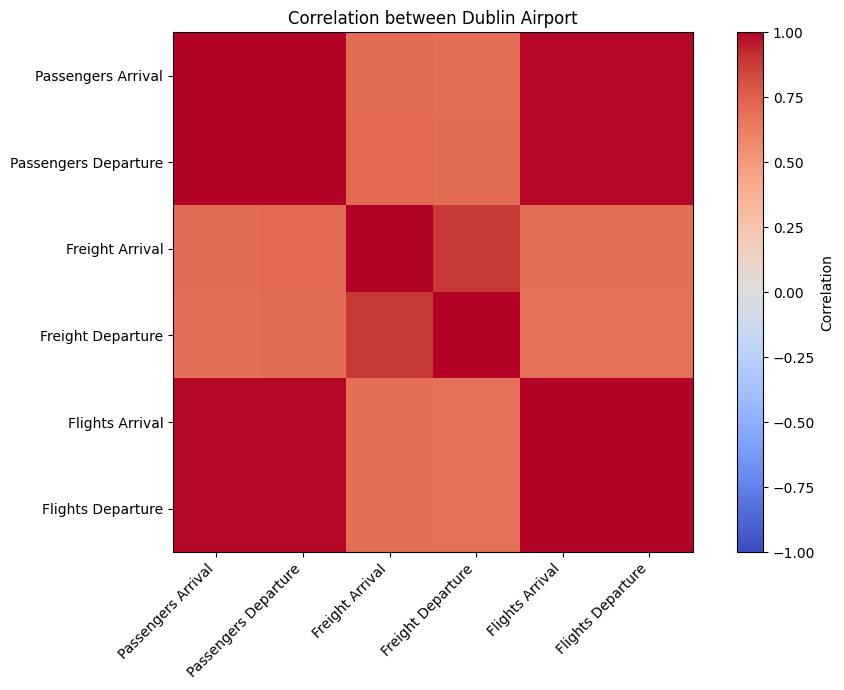

In [68]:
Correlations = dublin_monthly_table.select_dtypes(include='number').corr()
labels = Correlations.columns.tolist()
    
fig, ax = plt.subplots(figsize=(10,7))
    
image = ax.imshow(
    Correlations,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(6), labels=labels, rotation=45, ha='right')
ax.set_yticks(range(6), labels=labels)

fig.colorbar(image, ax=ax, label='Correlation')
ax.set_title('Correlation between Dublin Airport')

plt.tight_layout()
plt.show()

## Correlation Analysis
A correlation analysis was carried out to examine the relationships between the six mesuares. Passenger arrivals and departures have a very strong positive correlation of approximately 0.998, while flight arrivals and depertures have a correlation close to 1. Passanger and flight measures are also strongly correlated, with values of approximately 0.990. Freight has weaker positive correlations with passenger and flight measures, ranging from approximately 0.68 to 0.71. The heatmap illustrates these relationships. these findings suggest that some measures contains similar information, which should be considered when selecting feactures for clustering. 

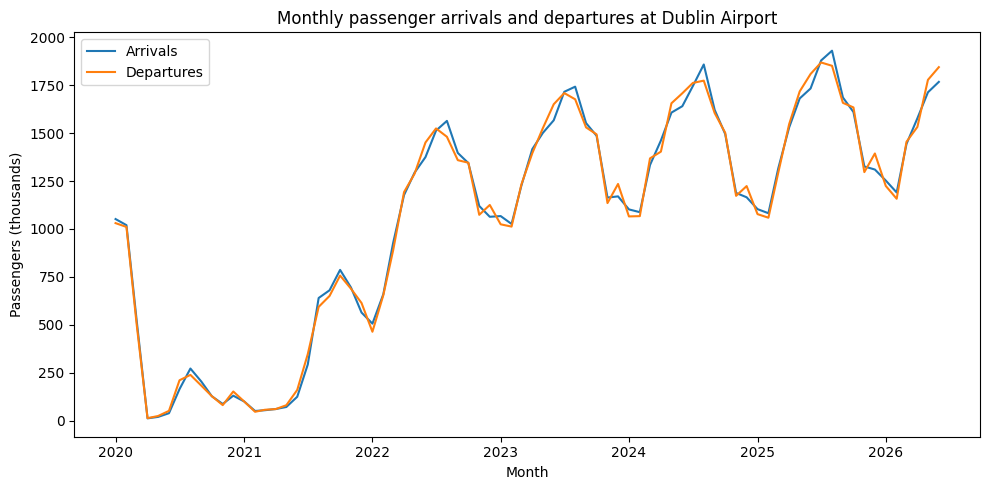

In [69]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(dublin_monthly_table['Month'], dublin_monthly_table['Passengers Arrival'], label='Arrivals')
ax.plot(dublin_monthly_table['Month'], dublin_monthly_table['Passengers Departure'], label='Departures')

ax.set_title('Monthly passenger arrivals and departures at Dublin Airport')
ax.set_xlabel('Month')
ax.set_ylabel('Passengers (thousands)')
ax.legend()

plt.tight_layout()
plt.show()


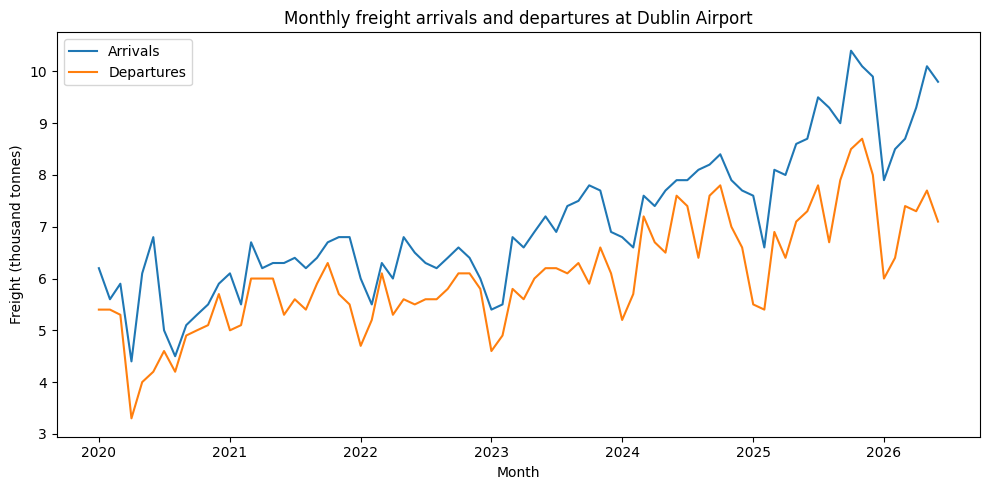

In [70]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(dublin_monthly_table['Month'], dublin_monthly_table['Freight Arrival'], label='Arrivals')
ax.plot(dublin_monthly_table['Month'], dublin_monthly_table['Freight Departure'], label='Departures')

ax.set_title('Monthly freight arrivals and departures at Dublin Airport')
ax.set_xlabel('Month')
ax.set_ylabel('Freight (thousand tonnes)')
ax.legend()

plt.tight_layout()
plt.show()

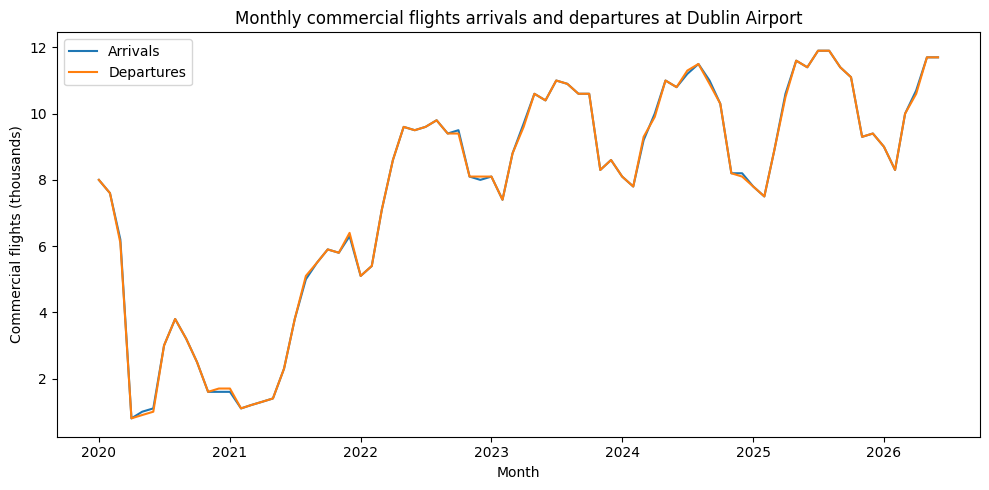

In [71]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(dublin_monthly_table['Month'], dublin_monthly_table['Flights Arrival'], label='Arrivals')
ax.plot(dublin_monthly_table['Month'], dublin_monthly_table['Flights Departure'], label='Departures')

ax.set_title('Monthly commercial flights arrivals and departures at Dublin Airport')
ax.set_xlabel('Month')
ax.set_ylabel('Commercial flights (thousands)')
ax.legend()

plt.tight_layout()
plt.show()

## Initial observations from monthly plots

Separate graphs  were created to understand  how activity changes over the time  before applying  the models. The first graph examined monthly passenger arrivals and departures. It showed a sharp decline in 2020, followed by an increase and recurring fluctuations from 2022 onwards.
The freight graph was used to explore whether  freight followed a similar pattern to passenger traffic. It showed fluctuations and an overall upward trend, with arrivals generally exceeding departures. The third graph examined commercial flight activity, which followed a pattern similar to passenger trafic. Flight arrivals and departures almost overlapped.
The decline in 2020 may be associated with the COVID-19 pandemic. However, this explanation requiresverification using an authoritative source rather than relying on the graph alone.

In [73]:
dublin_monthly_total = dublin_monthly_table.copy()

dublin_monthly_total['Passengers Total'] = (
    dublin_monthly_total['Passengers Arrival']
    + dublin_monthly_total['Passengers Departure']
)

dublin_monthly_total[
    ['Month','Passengers Arrival','Passengers Departure','Passengers Total']
].head()

,Month,Passengers Arrival,Passengers Departure,Passengers Total
0,2020-01-01,1051.9,1030.6,2082.5
1,2020-02-01,1020.0,1010.7,2030.7
2,2020-03-01,523.2,502.8,1026.0
3,2020-04-01,11.5,12.5,24.0
4,2020-05-01,19.0,23.7,42.7


In [74]:
dublin_monthly_total['Freight Total'] = (
    dublin_monthly_total['Freight Arrival']
    + dublin_monthly_total['Freight Departure']
)

dublin_monthly_total['Flights Total'] = (
    dublin_monthly_total['Flights Arrival']
    + dublin_monthly_total['Flights Departure']
)

dublin_monthly_total[
    ['Month','Passengers Total','Freight Total','Flights Total']
].head()

,Month,Passengers Total,Freight Total,Flights Total
0,2020-01-01,2082.5,11.6,16.0
1,2020-02-01,2030.7,11.0,15.2
2,2020-03-01,1026.0,11.2,12.3
3,2020-04-01,24.0,7.7,1.6
4,2020-05-01,42.7,10.1,1.9


In [75]:
x = dublin_monthly_total[['Passengers Total','Freight Total','Flights Total']].copy()

In [76]:
x.shape

(78, 3)

In [79]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [80]:
x_scaled.shape

(78, 3)

## Data preparation for clustering

Montly totals were calculated by adding arrivals and departures for passengers, freight and commercial flights. These three variables were selected to represent different aspects of airport activity and avoid incluiding arrivals and departures separately, as they were strongly correlated. The variables were standardised using StandarScaler so that differences would not dominate the clustering.

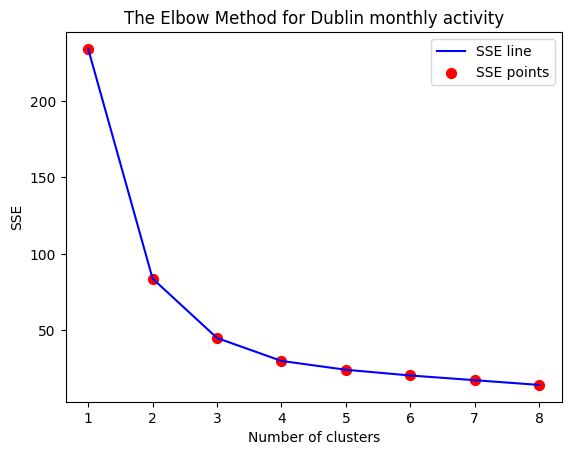

In [82]:
from sklearn.cluster import KMeans
sse = []  


for i in range(1, 9):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 38)  
    kmeans.fit(x_scaled)
    sse.append(kmeans.inertia_)                                                      


plt.plot(range(1, 9), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 9), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')

plt.title('The Elbow Method for Dublin monthly activity')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')  # sum of squares errors
plt.legend()
plt.show()

In [87]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score


for n_clusters in range(2, 9):
    kmeans = KMeans(n_clusters=n_clusters, max_iter=300, n_init=10, random_state=38)
    labels = kmeans.fit_predict(x_scaled) 
    score = silhouette_score(x_scaled, labels)
    db_score = davies_bouldin_score(x_scaled,labels)
    
    print(f"Silhouette Score (n = {n_clusters}): {score:.4f}")
    print(f"Davies-Bouldin Index (n = {n_clusters}): {db_score:.4f}")
    print()

Silhouette Score (n = 2): 0.5330
Davies-Bouldin Index (n = 2): 0.6659

Silhouette Score (n = 3): 0.4628
Davies-Bouldin Index (n = 3): 0.7023

Silhouette Score (n = 4): 0.4517
Davies-Bouldin Index (n = 4): 0.7556

Silhouette Score (n = 5): 0.4250
Davies-Bouldin Index (n = 5): 0.8020

Silhouette Score (n = 6): 0.4357
Davies-Bouldin Index (n = 6): 0.6712

Silhouette Score (n = 7): 0.4509
Davies-Bouldin Index (n = 7): 0.6634

Silhouette Score (n = 8): 0.4428
Davies-Bouldin Index (n = 8): 0.7188



In [90]:
kmeans = KMeans(
    n_clusters=2,
    max_iter=300,
    n_init=10,
    random_state=38
)

dublin_Kmeans = dublin_monthly_total.copy()
dublin_Kmeans['Cluster'] = kmeans.fit_predict(x_scaled)

In [92]:
dublin_Kmeans['Cluster'].value_counts().sort_index()

Cluster
0    28
1    50
Name: count, dtype: int64

In [93]:
dublin_Kmeans.groupby('Cluster')[
    ['Passengers Total','Freight Total','Flights Total']
].mean()

,Passengers Total,Freight Total,Flights Total
Cluster,,,
0,774.314286,11.078571,7.625
1,2877.540000,14.296000,19.636


In [94]:
dublin_Kmeans[
    ['Month','Cluster']
].sort_values('Month').head(30)

,Month,Cluster
0,2020-01-01,1
1,2020-02-01,0
2,2020-03-01,0
3,2020-04-01,0
4,2020-05-01,0
5,2020-06-01,0
6,2020-07-01,0
7,2020-08-01,0
8,2020-09-01,0
9,2020-10-01,0


In [95]:
pd.crosstab(
    dublin_Kmeans['Month'].dt.year,
    dublin_Kmeans['Cluster']
)

Cluster,0,1
Month,,
2020,11,1
2021,12,0
2022,3,9
2023,2,10
2024,0,12
2025,0,12
2026,0,6


## Kmeans clustering result

Kmeans was evaluated using two to eight clusters. Two clusters were selected because they achieved the highest Silhouette Score (0.5330), while their Davies-Bouldin Index (0.6659)was close to the lowest value, obtained with seven clusters (0.6634).Cluster 0 contains 28 months with lower average passenger, freight and flight activity. Cluster 1 contains 50 months with higher average activity. All months in 2021 belong to Cluster 0, while all available months from 2024 onwards belong to Cluster 1. This suggest that the groups mainly distinguish periods of lower and higher activity. A second clustering algorithm will be applied to compare the results.

In [97]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

for n_clusters in range (2, 9):
    hierarchical = AgglomerativeClustering(
        n_clusters = n_clusters,
        linkage='average'
    )
    hierarchical_labels = hierarchical.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, hierarchical_labels)
    db_score = davies_bouldin_score(x_scaled, hierarchical_labels)

    print(f"Silhouette Score (n = {n_clusters}): {score:.4f}")
    print(f"Davies Bouldin Index (n = {n_clusters}): {db_score:.4f}")
    print()

Silhouette Score (n = 2): 0.5531
Davies Bouldin Index (n = 2): 0.6120

Silhouette Score (n = 3): 0.4838
Davies Bouldin Index (n = 3): 0.6584

Silhouette Score (n = 4): 0.4274
Davies Bouldin Index (n = 4): 0.6743

Silhouette Score (n = 5): 0.4127
Davies Bouldin Index (n = 5): 0.6021

Silhouette Score (n = 6): 0.3769
Davies Bouldin Index (n = 6): 0.6087

Silhouette Score (n = 7): 0.4096
Davies Bouldin Index (n = 7): 0.7118

Silhouette Score (n = 8): 0.4255
Davies Bouldin Index (n = 8): 0.6106



In [98]:
hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage='average'
)

dublin_hierarchical = dublin_monthly_total.copy()
dublin_hierarchical['Cluster'] = hierarchical.fit_predict(x_scaled)

dublin_hierarchical['Cluster'].value_counts().sort_index() 

Cluster
0    54
1    24
Name: count, dtype: int64

In [99]:
dublin_hierarchical.groupby('Cluster')[
     ['Passengers Total','Freight Total','Flights Total']
].mean()

,Passengers Total,Freight Total,Flights Total
Cluster,,,
0,2812.122222,14.048148,19.300000
1,570.966667,11.100000,6.379167


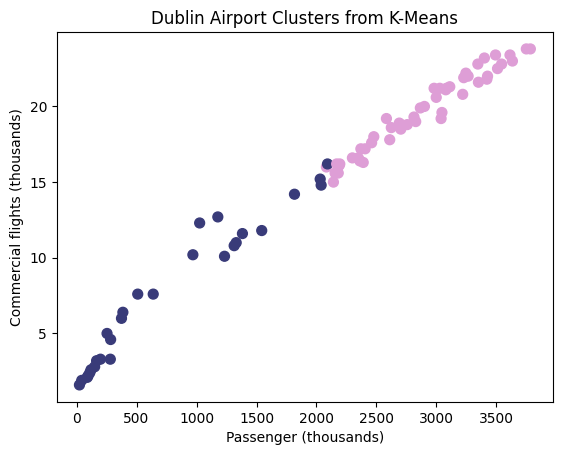

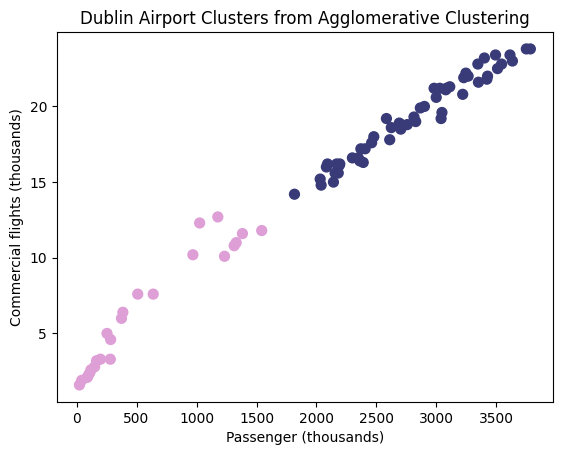

In [100]:
plt.title("Dublin Airport Clusters from K-Means")
plt.scatter(dublin_Kmeans['Passengers Total'], dublin_Kmeans['Flights Total'], c=dublin_Kmeans ['Cluster'], s=50, cmap='tab20b')


plt.xlabel("Passenger (thousands)")
plt.ylabel("Commercial flights (thousands)")
plt.show()

plt.title("Dublin Airport Clusters from Agglomerative Clustering")
plt.scatter(dublin_hierarchical['Passengers Total'], dublin_hierarchical ['Flights Total'], c=dublin_hierarchical  ['Cluster'], s=50, cmap='tab20b')


plt.xlabel("Passenger (thousands)")
plt.ylabel("Commercial flights (thousands)")
plt.show()


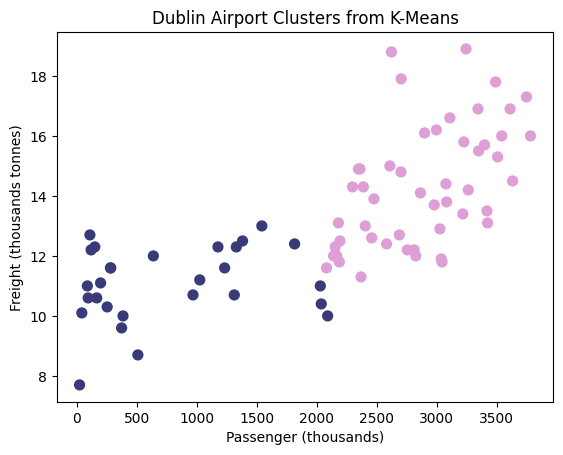

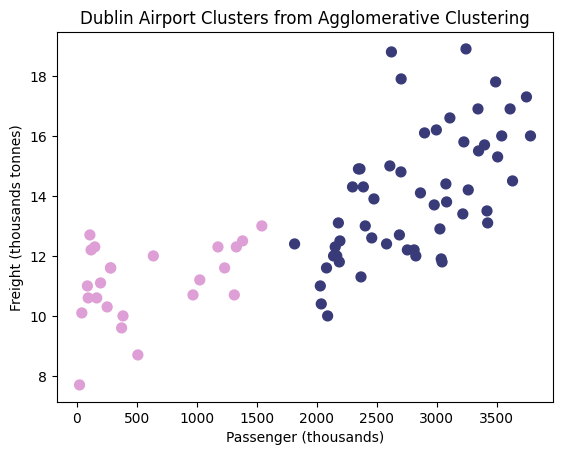

In [125]:
plt.title("Dublin Airport Clusters from K-Means")
plt.scatter(dublin_Kmeans['Passengers Total'], dublin_Kmeans['Freight Total'], c=dublin_Kmeans ['Cluster'], s=50, cmap='tab20b')


plt.xlabel("Passenger (thousands)")
plt.ylabel("Freight (thousands tonnes)")
plt.show()

plt.title("Dublin Airport Clusters from Agglomerative Clustering")
plt.scatter(dublin_hierarchical['Passengers Total'], dublin_hierarchical ['Freight Total'], c=dublin_hierarchical  ['Cluster'], s=50, cmap='tab20b')


plt.xlabel("Passenger (thousands)")
plt.ylabel("Freight (thousands tonnes)")
plt.show()

In [104]:
print("Silhouette Scores for Dublin Airport")
print("K-Means:", silhouette_score(x_scaled, dublin_Kmeans['Cluster']))
print("Agglomerative: ", silhouette_score(x_scaled, dublin_hierarchical['Cluster']))

print ("\nDavies-Bouldin Indices for Dublin Airport:")
print("K-Means:", davies_bouldin_score(x_scaled, dublin_Kmeans['Cluster']))

print ("Agglomerative:", davies_bouldin_score (x_scaled, dublin_hierarchical['Cluster']))


Silhouette Scores for Dublin Airport
K-Means: 0.5330009878021635
Agglomerative:  0.553073948221985

Davies-Bouldin Indices for Dublin Airport:
K-Means: 0.6659350308575078
Agglomerative: 0.6119558146299428


## Comparison Clustering
KMeans and agglomerative clustering were compared using the same three standardised variables: monthly passenger, freight and commercial flight totals. For the two-cluster solutions, agglomerative clustering achieved a higher Silhouette Score (0.5531 versus 0.5330) and a lower Davies–Bouldin Index (0.6120 versus 0.6659). A higher Silhouette Score indicates better cohesion and separation, while a lower Davies–Bouldin Index indicates less similarity between clusters relative to their internal spread.

Both methods identified months with lower and higher average activity. KMeans assigned 28 months to the lower-activity group and 50 to the higher-activity group, while agglomerative clustering assigned 24 and 54 months, respectively. The scatter plots show the relationships between passengers and flights, and between passengers and freight, with differences in the assignment of some months with intermediate activity.

The two-cluster agglomerative solution was preferred because it achieved better results on both metrics, although the improvement was modest. The strong correlation between passengers and flights represents a limitation, as these variables provide similar information. The groups describe activity levels and should not automatically be interpreted as seasonal categories that recur each year.


In [105]:
passenger_series = (dublin_monthly_total.set_index('Month')['Passengers Total'].sort_index().asfreq('MS'))

passenger_series.head()

Month
2020-01-01    2082.5
2020-02-01    2030.7
2020-03-01    1026.0
2020-04-01      24.0
2020-05-01      42.7
Freq: MS, Name: Passengers Total, dtype: float64

In [106]:
passenger_series.info()

<class 'pandas.core.series.Series'>
DatetimeIndex: 78 entries, 2020-01-01 to 2026-06-01
Freq: MS
Series name: Passengers Total
Non-Null Count  Dtype  
--------------  -----  
78 non-null     float64
dtypes: float64(1)
memory usage: 1.2 KB


In [108]:
print("Missing values:",passenger_series.isna().sum())

Missing values: 0


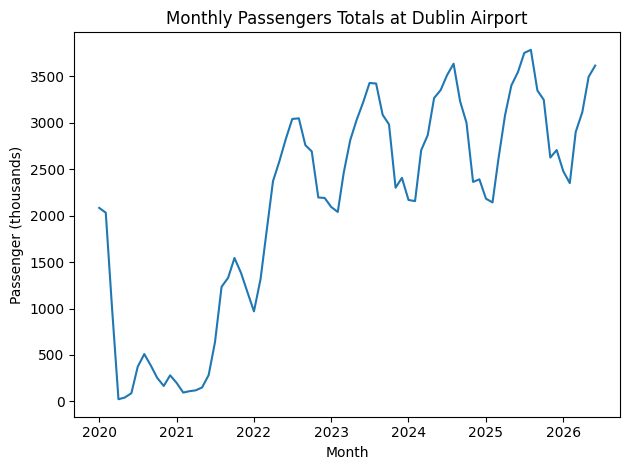

In [109]:
plt.plot(passenger_series)

plt.title("Monthly Passengers Totals at Dublin Airport")
plt.xlabel("Month")
plt.ylabel("Passenger (thousands)")

plt.tight_layout()
plt.show()

In [113]:
train = passenger_series.iloc[:-12].copy()
test = passenger_series.iloc[-12:].copy()

print("training:", len(train), "months")
print(train.index.min(), "to", train.index.max())  

print("\nTest:", len(test), "months")
print(test.index.min(), "to", test.index.max())

training: 66 months
2020-01-01 00:00:00 to 2025-06-01 00:00:00

Test: 12 months
2025-07-01 00:00:00 to 2026-06-01 00:00:00


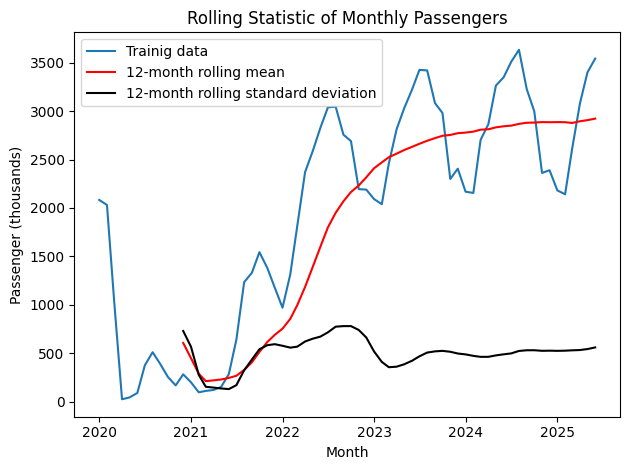

In [115]:
rolling_mean = train.rolling(window=12).mean()
rolling_std = train.rolling(window=12).std()

plt.plot(train, label='Trainig data')
plt.plot(rolling_mean, color='red', label='12-month rolling mean')
plt.plot(rolling_std, color='black', label='12-month rolling standard deviation')

plt.title("Rolling Statistic of Monthly Passengers")
plt.xlabel("Month")
plt.ylabel("Passenger (thousands)")
plt.legend()

plt.tight_layout()
plt.show()

The 12 month rolling mean changes substantially over the training period, while  the rolling standard deviation also varies. this suggestthatthe series may not be stationary. An ADF test will be used to investigate this further.

In [118]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train)
print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
for level, value in adf_result[4].items():
    print(f"Critical Value ({level}): {value}")

ADF statistic: -0.8523764185626719
p-value: 0.803250942147371
Critical Value (1%): -3.5463945337644063
Critical Value (5%): -2.911939409384601
Critical Value (10%): -2.5936515282964665


The ADF test returned a p-value of 0.8033, so the unit root null hypothesis was not rejected at the 5% significance level. Together with the changing rolling mean, this supports investigating differencing before modelling.

In [120]:
train_diff = train.diff().dropna()

train_diff.head()

Month
2020-02-01     -51.8
2020-03-01   -1004.7
2020-04-01   -1002.0
2020-05-01      18.7
2020-06-01      46.2
Freq: MS, Name: Passengers Total, dtype: float64

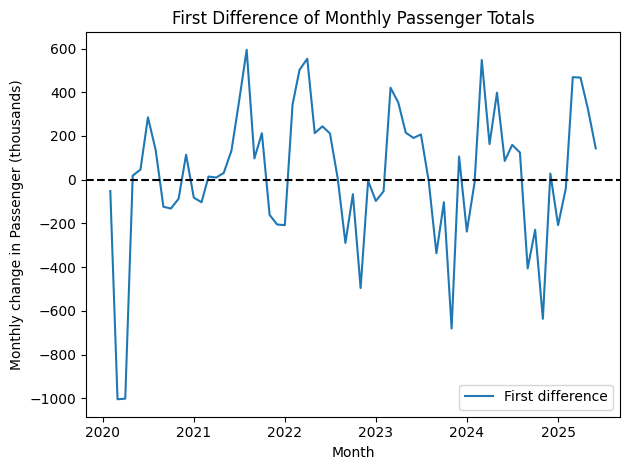

In [122]:
plt.plot(train_diff, label="First difference")
plt.axhline(0, color="black", linestyle="--")

plt.title("First Difference of Monthly Passenger Totals")
plt.xlabel("Month")
plt.ylabel("Monthly change in Passenger (thousands)")
plt.legend()

plt.tight_layout()
plt.show()

In [124]:
adf_diff = adfuller(train_diff)
print("ADF statistic:", adf_diff[0])
print("p-value:", adf_diff[1])
for level, value in adf_diff[4].items():
    print(f"Critical Value ({level}): {value}")

ADF statistic: -1.837632833113856
p-value: 0.36194449141575846
Critical Value (1%): -3.560242358792829
Critical Value (5%): -2.9178502070837
Critical Value (10%): -2.5967964150943397


After first differencing, the ADF p-value decresed from 0.8033 to 0.3619 but remained above 0.05.The unit root null hypothesis was therefore not rejected. Seasonal patterns will be investigated before deciding wheter further differencing is appropriate.

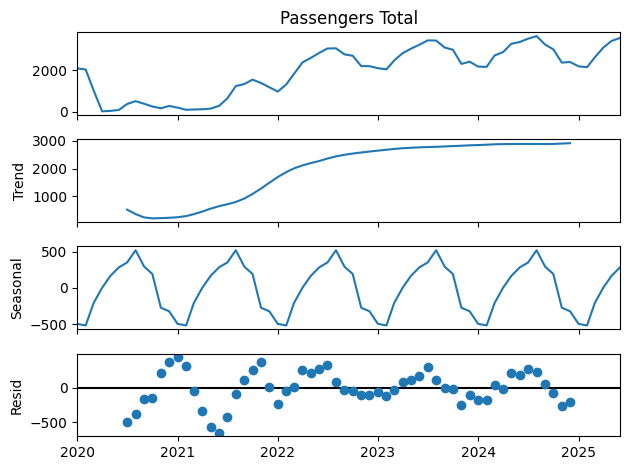

In [127]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(train, model="additive", period=12)

fig = decomposition.plot()
plt.tight_layout()
plt.show()

The additive decomposition shows an increasing trend followed by relative stabilisation and an estimated annual seasonal pattern. Remaining patters in the residuals suggest that trend and seasonality do not explain all variation. The seasonal component is fixed by decomposition method and does not confirm a stable pattern  throughout the entire period.

In [128]:
train_seasonal_diff = train.diff(12).dropna()

adf_seasonal = adfuller(train_seasonal_diff)

print("Observations:", len(train_seasonal_diff))
print("ADF Statistic:", adf_seasonal[0])
print("p-value:", adf_seasonal[1])

Observations: 54
ADF Statistic: -2.789622619308526
p-value: 0.059771460917853125


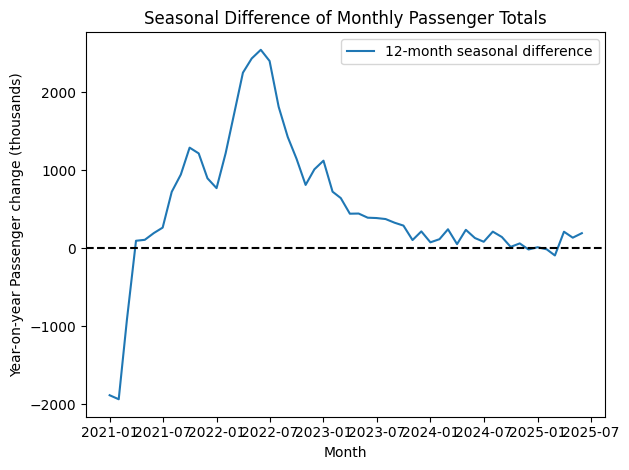

In [129]:
plt.plot(train_seasonal_diff, label="12-month seasonal difference")
plt.axhline(0, color="black", linestyle="--")

plt.title("Seasonal Difference of Monthly Passenger Totals")
plt.xlabel("Month")
plt.ylabel("Year-on-year Passenger change (thousands)")
plt.legend()

plt.tight_layout()
plt.show()

Seasonal differencing shows large year-on-year changes in 2021-2022, followed by smaller changes from  2024 onwards. The ADF p-value was 0.0598, so the unit root null hypothesis was not rejected at 5% level.

In [130]:
train_combined_diff = train.diff(12).diff().dropna()

adf_combined = adfuller(train_combined_diff)

print("Observations:", len(train_combined_diff))
print("ADF Statistic:", adf_combined[0])
print("p-value:", adf_combined[1])

Observations: 53
ADF Statistic: -4.428247235233056
p-value: 0.0002644670334061973


after applying first and seasonal differencing, the ADF p-value was 0.0002644. The unit root null hypothesis was rejected at the 5% level, supporting d=1 and D=1 as candidate differencing ordersfor SARIMA. 

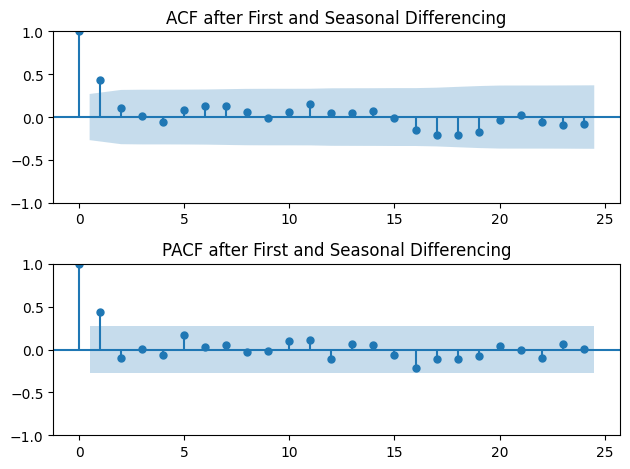

In [132]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2,1)

plot_acf(train_combined_diff, lags=24, ax=axes[0])
plot_pacf(train_combined_diff, lags=24, method="ywm", ax=axes[1])

axes[0].set_title("ACF after First and Seasonal Differencing")
axes[1].set_title("PACF after First and Seasonal Differencing")

plt.tight_layout()
plt.show()

After the first and seasonal differencing, both ACF and PACF shows a significant spike at lag 1, while most remaining lags fall within the confidence bands. This supports investigating low-order AR an MA terms. No prominent spike is observed at lag 12, so seasonal AR and MA terms will not be assumed necessary.

In [139]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

candidate_orders = [
    (1,1,0),
    (0,1,1),
    (1,1,1)
]

sarima_models = {}
model_results = []

for order in candidate_orders: 
    model = SARIMAX(train, order=order, seasonal_order=(0,1,0,12))

    fitted_model = model.fit(disp=False)
    sarima_models[order] = fitted_model

    model_results.append({
        "Order": str(order),
        "Seasonal order": "(0,1,0,12)",
        "AIC": fitted_model.aic,
        "Converged": fitted_model.mle_retvals.get("converged", False)
    })

sarima_comparison = pd.DataFrame(model_results)
sarima_comparison.sort_values("AIC")

,Order,Seasonal order,AIC,Converged
1,"(0, 1, 1)","(0,1,0,12)",744.941380,True
0,"(1, 1, 0)","(0,1,0,12)",745.963991,True
2,"(1, 1, 1)","(0,1,0,12)",746.660594,True


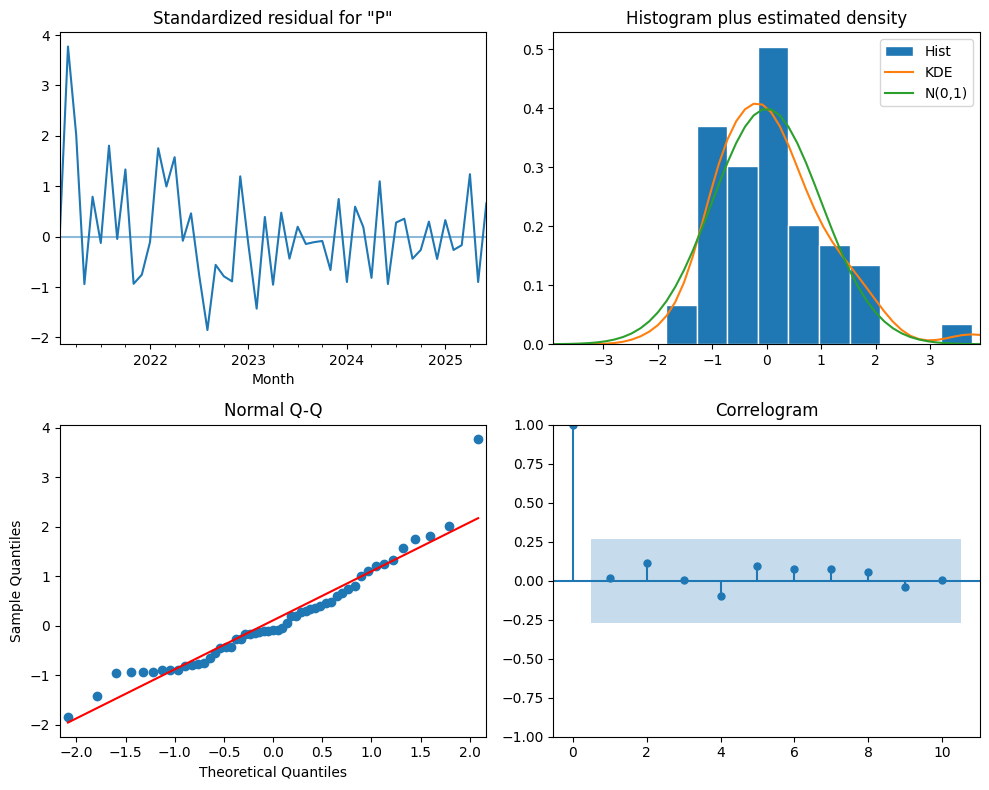

In [141]:
select_model = sarima_models[(0,1,1)]

select_model.plot_diagnostics(figsize=(10,8))

plt.tight_layout()
plt.show()

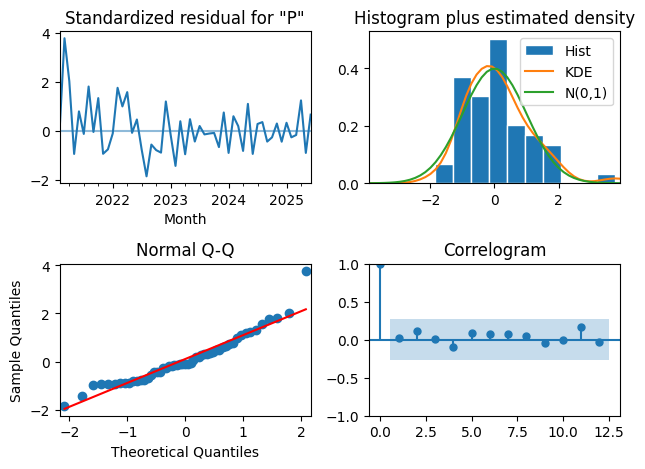

In [146]:
selected_model = sarima_models[(0,1,1)]

selected_model.plot_diagnostics(lags=12)

plt.tight_layout()
plt.show()

In [149]:
forecast_result = selected_model.get_forecast(steps=len(test))

sarima_forecast = forecast_result.predicted_mean
forecast_interval = forecast_result.conf_int(alpha=0.05)

sarima_forecast.head()

2025-07-01    3787.599913
2025-08-01    3911.799913
2025-09-01    3505.899913
2025-10-01    3276.699913
2025-11-01    2639.999913
Freq: MS, Name: predicted_mean, dtype: float64

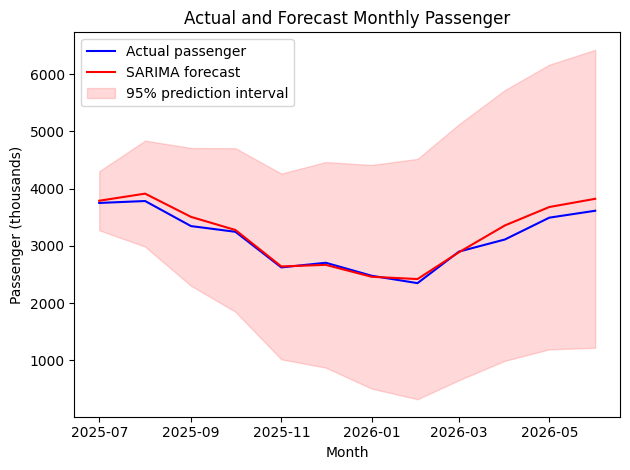

In [155]:
plt.plot(test, label="Actual passenger", color="blue")
plt.plot(sarima_forecast, label="SARIMA forecast", color="red")

plt.fill_between(forecast_interval.index, forecast_interval.iloc[:,0], forecast_interval.iloc[:,1], color="red", alpha=0.15, label="95% prediction interval")

plt.title("Actual and Forecast Monthly Passenger")
plt.xlabel("Month")
plt.ylabel("Passenger (thousands)")
plt.legend()

plt.tight_layout()
plt.show()

In [156]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, sarima_forecast)
rmse = np.sqrt(mean_squared_error(test, sarima_forecast))
mape= np.mean(np.abs((test - sarima_forecast) / test)) * 100

print ("MAE (thousands passengers):", round(mae,2))
print ("RMSE (thousands passengers):", round(rmse,2))
print ("MAPE (%):", round(mape,2))

MAE (thousands passengers): 96.04
RMSE (thousands passengers): 125.94
MAPE (%): 2.94


In [162]:
seasonal_naive = pd.Series(train.tail(12).to_numpy(), index=test.index)

print("Seasonal naive MAE:",
      round(mean_absolute_error(test, seasonal_naive), 2))

print("Seasonal naive RMSE:",
      round(np.sqrt(mean_squared_error(test, seasonal_naive)), 2))

print("Seasonal naive MAPE (%):",
      round(np.mean(np.abs((test - seasonal_naive)/ test)) * 100, 2))
      

Seasonal naive MAE: 193.39
Seasonal naive RMSE: 214.48
Seasonal naive MAPE (%): 6.63


## SARIMA evaluation and limitations
Based on the results obtained, SARIMA (0,1,1)(0,1,0,12) was selected because it achieved the lowest AIC among the three models evaluated using the training data. During the 12-month test period, SARIMA achieved a MAPE of 2.94%, compared with 6.63% for the seasonal naïve method, which repeats the previous year’s values. Its mean absolute error was approximately 96,040 passengers per month. These results were favourable compared with the benchmark during the evaluation period. However, the evaluation covered a single 12-month test period, so the results do not guarantee the same accuracy in future periods. Furthermore, the residuals show greater variability at the beginning than at the end of the analysed period, suggesting that the magnitude of the errors is not constant and should be acknowledged as a model limitation.

The residuals fluctuate around zero, although a positive outlier indicates that the model underestimated the number of passengers for one observation. In the correlogram, lags 1 to 12 remain within the confidence bands, providing no clear visual evidence of residual autocorrelation at those lags. This suggests that the model has captured much of the temporal dependence, although it does not guarantee that the errors are independent.